# A shared year effect and each country's deviation from it

How much of the change in recorded events over 1990 to 2023 is common to the eleven countries of 14, and how much belongs to each country?

The model is 14's with its year effect split in two: one curve over years shared by the region, and for each country a deviation from it, with the deviations summing to zero across countries in every year. The shared curve is then the region's average year effect and each deviation how far a country departs from it. Both are recorded events, so the shared curve carries EM-DAT's coverage growing over the record together with any change in hazard, and this record does not separate the two. Geography, covariates, population and the record are 14's, rebuilt here.

In [19]:
from pathlib import Path

import arviz as az
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import pymc as pm
import pytensor.tensor as pt
import xarray as xr

from climate_risk import load_shapefile
from climate_risk.data.cell_samples import load_cell_distances_to, load_cell_unit_overlaps
from climate_risk.data.fetch import fetch
from climate_risk.data.gadm import administered_territories, load_units_in_country
from climate_risk.data.geo_disasters import load_resolved_units
from climate_risk.data.ghsl import population_on_cells
from climate_risk.data.hadcrut import HADCRUT
from climate_risk.data_functions.emdat_processing import DISASTER_CLASSES, event_geography, load_emdat_events
from climate_risk.data_functions.rivers_data_loader import load_rivers_data
from climate_risk.geo.crs import PROJECTED_CRS, to_km
from climate_risk.geo.raster import build_cell_grid, dissolve_place_boundary
from climate_risk.models.aggregation import Aggregation
from climate_risk.plotting import configure_plot_style, prepare_gridspec_figure

configure_plot_style()

CACHE_DIR = Path("../../data")
COUNTRIES = ("PAK", "IND", "NPL", "BTN", "BGD", "LKA", "MMR", "THA", "LAO", "KHM", "VNM")
SEED = 20261025

## Geography, covariates and the record

As in 14: one 25 km lattice over the eleven countries, the four hazard covariates, each unit's population as its coverage share of the atoms it overlaps, and EM-DAT's events placed on GADM units.

In [2]:
RESOLUTION_KM = 25.0
LEVELS = ("ADM2", "ADM1", "ADM0")

# GADM files the territories a country administers in Kashmir and along its disputed borders under codes of their own.
codes_of = {iso: (iso, *administered_territories(iso, CACHE_DIR)) for iso in COUNTRIES}
units = {level: pd.concat([load_units_in_country(code, admin, CACHE_DIR).assign(country=iso) for iso, codes in codes_of.items() for code in codes],
                          ignore_index=True)
         for level, admin in [("ADM2", 2), ("ADM1", 1)]}
boundary = gpd.GeoDataFrame(pd.concat([dissolve_place_boundary(units["ADM1"].loc[units["ADM1"]["country"] == iso, ["geometry"]], iso3=iso) for iso in COUNTRIES],
                                      ignore_index=True))
units["ADM0"] = gpd.GeoDataFrame({"gid": list(COUNTRIES), "name": list(COUNTRIES), "admin_level": 0, "country": list(COUNTRIES)},
                                 geometry=boundary.geometry.to_numpy(),
                                 crs=boundary.crs)
grid = build_cell_grid(boundary, resolution_km=RESOLUTION_KM)
atoms = grid.cells.reset_index(drop=True)
n_atoms = len(atoms)
column_of_cell = pd.Series(np.arange(n_atoms), index=atoms["cell_id"].to_numpy())

# Every (atom, unit) pair that overlaps, with units as positions into units[level].
overlaps = {}
for level in LEVELS:
    pairs = load_cell_unit_overlaps(grid, units[level], CACHE_DIR)
    position = pd.Series(np.arange(len(units[level])), index=units[level]["gid"].to_numpy())
    overlaps[level] = pd.DataFrame({"atom": column_of_cell.loc[pairs["cell_id"]].to_numpy(),
                                    "unit": position.loc[pairs["gid"]].to_numpy(),
                                    "coverage": pairs["coverage"].to_numpy()})

# The unit covering most of each atom, which is the unit an event centered there is reported in.
unit_of_atom = {level: overlaps[level].sort_values("coverage", ascending=False).drop_duplicates("atom").set_index("atom")["unit"].reindex(np.arange(n_atoms)).to_numpy()
                for level in LEVELS}
n_units = {level: len(units[level]) for level in LEVELS}
unit_offset = dict(zip(LEVELS, np.cumsum([0, *[n_units[level] for level in LEVELS[:-1]]]), strict=True))
n_all_units = sum(n_units.values())
country_of_atom = unit_of_atom["ADM0"]
n_countries = len(COUNTRIES)

pd.DataFrame({
    "atoms": np.bincount(country_of_atom, minlength=n_countries),
    **{f"{level} units": units[level]["country"].value_counts().reindex(COUNTRIES, fill_value=0).to_numpy() for level in ("ADM2", "ADM1")},
}, index=list(COUNTRIES))

,atoms,ADM2 units,ADM1 units
PAK,1620,32,8
IND,5402,676,41
NPL,278,14,5
BTN,74,205,20
BGD,250,64,8
LKA,132,323,25
MMR,1231,63,15
THA,890,928,77
LAO,368,142,18
KHM,296,202,25


In [3]:
COVARIATE_NAMES = ("log distance to river", "log discharge of nearest river", "distance by discharge", "log distance to coast")
# The nearest coast of an inland atom lies inside the region's bounds widened by this many degrees.
SHORELINE_MARGIN_DEGREES = 5.0


def standardized(values):
    """Values shifted to mean zero and scaled to unit standard deviation."""
    return (values - values.mean()) / values.std()


west, south, east, north = boundary.total_bounds
rivers = load_rivers_data(CACHE_DIR)
nearest_river = load_cell_distances_to(grid, rivers.cx[west - 1:east + 1, south - 1:north + 1], CACHE_DIR, return_columns=["DIS_AV_CMS"])
river_km = to_km(nearest_river["distance_to_closest"].to_numpy())
river_discharge = nearest_river["DIS_AV_CMS"].to_numpy()
shoreline = load_shapefile("coastline", CACHE_DIR).boundary.clip((west - SHORELINE_MARGIN_DEGREES,
                                                                  south - SHORELINE_MARGIN_DEGREES,
                                                                  east + SHORELINE_MARGIN_DEGREES,
                                                                  north + SHORELINE_MARGIN_DEGREES))
coast_km = to_km(load_cell_distances_to(grid, shoreline[~shoreline.is_empty], CACHE_DIR)["distance_to_closest"].to_numpy())

river_distance_z = standardized(np.log(river_km + 1.0))
discharge_z = standardized(np.log(river_discharge))
covariates = np.column_stack([river_distance_z,
                              discharge_z,
                              river_distance_z * discharge_z,
                              standardized(np.log(coast_km + 1.0))])

# Projected atom centers, scaled so the longer side of the region spans one unit, the domain the lengthscale prior is set on.
projected = atoms.to_crs(PROJECTED_CRS).geometry
atom_xy = np.column_stack([projected.x, projected.y])
DOMAIN_KM = to_km(np.ptp(atom_xy, axis=0).max())
atom_centroids = (atom_xy - atom_xy.min(axis=0)) / np.ptp(atom_xy, axis=0).max()

In [4]:
POPULATION_EPOCH = 2005

# A unit holds its coverage share of every atom it overlaps, so a unit smaller than an atom still holds its people.
population = population_on_cells(grid, POPULATION_EPOCH, CACHE_DIR)
unit_population = {level: np.bincount(overlaps[level]["unit"],
                                      weights=population[overlaps[level]["atom"]] * overlaps[level]["coverage"],
                                      minlength=n_units[level])
                   for level in LEVELS}
population_z = np.concatenate([standardized(np.log(np.maximum(unit_population[level], 1.0))) for level in LEVELS])

In [5]:
FIRST_YEAR, LAST_YEAR = 1990, 2023
LEVEL_OF_ADMIN = {2: "ADM2", 1: "ADM1"}

events = load_emdat_events(CACHE_DIR).filter(
    pl.col("ISO").is_in(list(COUNTRIES))
    & pl.col("Disaster Type").is_in(list(DISASTER_CLASSES))
    & pl.col("date").dt.year().is_between(FIRST_YEAR, LAST_YEAR)
)
resolved = pl.from_pandas(load_resolved_units(list(COUNTRIES), CACHE_DIR)).select(
    pl.col("DisNo."),
    pl.col("gid"),
    pl.col("name"),
    pl.col("admin_level").cast(pl.Int8),
    pl.col("geocoding_q").cast(pl.Int8),
    pl.col("overlap"),
)
geography = event_geography(events, resolved=resolved)

unit_position = {level: pd.Series(np.arange(n_units[level]), index=units[level]["gid"].to_numpy()) for level in ("ADM2", "ADM1")}
country_position = pd.Series(np.arange(n_countries), index=list(COUNTRIES))


def named_units(rows, iso):
    """The units an event filed under ``iso`` names in that country, as positions into units[level], keyed by level."""
    named = {}
    for admin, gid in rows.filter(pl.col("gid").is_not_null()).select("admin_level", "gid").iter_rows():
        level = LEVEL_OF_ADMIN[admin]
        if gid in unit_position[level].index and units[level]["country"].iloc[unit_position[level].loc[gid]] == iso:
            named.setdefault(level, set()).add(int(unit_position[level].loc[gid]))

    return {level: tuple(sorted(found)) for level, found in named.items()}


event_rows = []
for (disno, iso), rows in geography.group_by("DisNo.", "ISO", maintain_order=True):
    named = named_units(rows, iso)
    event_rows.append({
        "DisNo.": disno,
        "country": iso,
        "level": "ADM1" if "ADM1" in named else "ADM2" if named else "ADM0",
        "named": named or {"ADM0": (int(country_position[iso]),)},
    })

record = pd.DataFrame(event_rows).merge(events.select("DisNo.", pl.col("date").dt.year().alias("year")).to_pandas(), on="DisNo.")

record.groupby(["country", "level"]).size().unstack(fill_value=0).reindex(COUNTRIES).assign(events=lambda frame: frame.sum(axis=1))

level,ADM0,ADM1,ADM2,events
country,,,,
PAK,51,81,32,164
IND,15,283,154,452
NPL,6,8,66,80
BTN,2,4,1,7
BGD,33,29,148,210
LKA,3,28,59,90
MMR,2,29,24,55
THA,14,113,15,142
LAO,9,22,5,36


## The model

14's model with one change, in the year effect. Each country's year effect is a shared curve plus its own deviation,

$$\text{year effect}_{c,t} = s_t + d_{c,t}, \qquad \sum_c d_{c,t} = 0 \text{ for every } t,$$

where both $s$ and $d$ are Matern 5/2 processes over years on one Hilbert space basis, each with its own amplitude and lengthscale. The deviations' coefficients are zero-sum over countries, and a zero sum over coefficients is a zero sum over the curves they build, since the map from one to the other is linear. The shared amplitude's prior is 14's, half-normal with scale 0.5, and the deviations' is half-normal with scale 0.3, so a common shape goes to the shared curve unless the countries' records disagree. Both lengthscale priors are 14's, with their mode at 5 years.

In [6]:
HSGP_BOUNDARY_FACTOR = 4.0
HSGP_KM_PER_BASIS = 70.0
FIELD_LENGTHSCALE_MODE_KM = 340.0
YEAR_BOUNDARY_FACTOR = 1.5
YEAR_BASIS = 20
SHARED_YEAR_AMPLITUDE_PRIOR = 0.5
DEVIATION_YEAR_AMPLITUDE_PRIOR = 0.3
OFFSET_SD_PRIOR = 0.5
OFFSET_LEVELS = ("ADM2", "ADM1")
# A prior guess at the density of event centers over the whole record, recorded or not, which fixes where each intercept sits.
PRIOR_EVENT_CENTERS_PER_ATOM = 0.18
sample_kwargs = {
    "chains": 8,
    "cores": 8,
    "tune": 500,
    "draws": 250,
    "random_seed": SEED,
}

In [7]:
years = np.arange(FIRST_YEAR, LAST_YEAR + 1)
YEARS = len(years)
annual_observed = record.groupby(["country", "year"]).size().unstack(fill_value=0).reindex(index=list(COUNTRIES), columns=years, fill_value=0).to_numpy()
field_basis = np.ceil(to_km(np.ptp(atom_xy, axis=0)) / HSGP_KM_PER_BASIS).astype(int).tolist()
atom_country = np.eye(n_countries)[country_of_atom].T

# Each (level, atom) in one flat index, level-major, and the all-units index of the atom's unit at that level.
center_unit = np.concatenate([unit_offset[level] + unit_of_atom[level] for level in LEVELS])


def union_cells(named, country):
    """The (level, atom) cells of an event's union inside ``country``, the atoms its record's share is taken over, read at the level it is reported at."""
    level = "ADM1" if "ADM1" in named else next(iter(named))
    atoms_named = np.unique(np.concatenate([overlaps[at]["atom"][overlaps[at]["unit"].isin(found)].to_numpy() for at, found in named.items()]))
    atoms_named = atoms_named[country_of_atom[atoms_named] == country]

    return LEVELS.index(level), LEVELS.index(level) * n_atoms + atoms_named


record_key = record.apply(lambda event: (event["country"], tuple(sorted(event["named"].items()))), axis=1)
distinct = record.assign(key=record_key).groupby("key", sort=False).agg(multiplicity=("DisNo.", "size"), named=("named", "first"), country=("country", "first"))
distinct_country = country_position.loc[distinct["country"]].to_numpy()
cells_by_record = [union_cells(named, country) for named, country in zip(distinct["named"], distinct_country, strict=True)]
detection_terms = {
    "multiplicity": distinct["multiplicity"].to_numpy(),
    "country": distinct_country,
    "union": Aggregation(units=tuple(f"record {index}" for index in range(len(distinct))),
                         rows=np.repeat(np.arange(len(distinct)), [len(cells) for _, cells in cells_by_record]),
                         columns=np.concatenate([cells for _, cells in cells_by_record]),
                         weights=np.ones(sum(len(cells) for _, cells in cells_by_record)),
                         n_cells=len(LEVELS) * n_atoms),
}
COORDS = {
    "country": list(COUNTRIES),
    "covariate": list(COVARIATE_NAMES),
    "atom": np.arange(n_atoms),
    "unit": np.arange(n_all_units),
    "level": list(LEVELS),
    "record": detection_terms["union"].units,
    "year": years,
    "year_basis": np.arange(YEAR_BASIS),
    **{level: units[level]["gid"].to_list() for level in OFFSET_LEVELS},
}

In [17]:
def latent_log_rate():
    """The log rate of event centers at every atom, built inside the current model."""
    intercept = pm.Normal("intercept",
                          mu=np.log(PRIOR_EVENT_CENTERS_PER_ATOM),
                          sigma=1.0,
                          dims="country")
    slopes = pm.Normal("slopes",
                       mu=0.0,
                       sigma=1.0,
                       dims="covariate")

    # Mode at FIELD_LENGTHSCALE_MODE_KM, in units of the region's longer side.
    field_lengthscale = pm.InverseGamma("field_lengthscale",
                                        alpha=3.0,
                                        beta=4.0 * FIELD_LENGTHSCALE_MODE_KM / DOMAIN_KM)
    field_amplitude = pm.HalfNormal("field_amplitude", sigma=1.0)
    gp = pm.gp.HSGP(m=field_basis,
                    c=HSGP_BOUNDARY_FACTOR,
                    cov_func=field_amplitude**2 * pm.gp.cov.Matern32(input_dim=2, ls=field_lengthscale))
    field = gp.prior("field", X=atom_centroids, dims="atom")

    offset_part = 0.0
    for level in OFFSET_LEVELS:
        offset_sd = pm.HalfNormal(f"{level}_offset_sd", sigma=OFFSET_SD_PRIOR)
        standard = pm.Normal(f"{level}_offset_standard",
                             mu=0.0,
                             sigma=1.0,
                             dims=level)
        offsets = pm.Deterministic(f"{level}_offset", offset_sd * standard, dims=level)
        offset_part = offset_part + offsets[unit_of_atom[level]]

    return pm.Deterministic("log_rate",
                            intercept[country_of_atom] + pm.math.dot(covariates, slopes) + field + offset_part,
                            dims="atom")


def recorded_intensity():
    """Recorded events per (level, atom) over the record: centers, times the level's share in the atom's country, times detection by the center's unit there."""
    rate = pm.math.exp(latent_log_rate())
    naming_intercept = pm.Normal("naming_intercept",
                                 mu=0.0,
                                 sigma=1.5)
    naming_slope = pm.Normal("naming_slope",
                             mu=0.0,
                             sigma=1.0)
    naming = pm.Deterministic("naming_probability",
                              pm.math.invlogit(naming_intercept + naming_slope * population_z),
                              dims="unit")
    # GADM's levels are different kinds of unit in each country, so each country reports across them in its own proportions.
    level_probability = pm.Dirichlet("level_probability",
                                     a=np.ones((n_countries, len(LEVELS))),
                                     dims=("country", "level"))

    return level_probability[country_of_atom].T * rate[None, :] * naming[center_unit].reshape((len(LEVELS), n_atoms))


def year_process_weights(name, amplitude_prior):
    """A Matern 5/2 process over years, as its amplitude, lengthscale and the square root of its spectral density on the shared basis."""
    # Mode at 5 years, so the process follows changes in reporting over a few years and leaves single years to the dispersion.
    lengthscale = pm.InverseGamma(f"{name}_lengthscale",
                                  alpha=3.0,
                                  beta=20.0)
    amplitude = pm.HalfNormal(f"{name}_amplitude", sigma=amplitude_prior)
    gp = pm.gp.HSGP(m=[YEAR_BASIS],
                    c=YEAR_BOUNDARY_FACTOR,
                    cov_func=amplitude**2 * pm.gp.cov.Matern52(input_dim=1, ls=lengthscale))

    return gp.prior_linearized(X=years[:, None].astype(float))


def shared_year_process():
    """The smooth curve over years shared by the region."""
    year_basis, shared_sqrt_psd = year_process_weights("shared_year", SHARED_YEAR_AMPLITUDE_PRIOR)
    shared_coefficients = pm.Normal("shared_year_coefficients",
                                    mu=0.0,
                                    sigma=1.0,
                                    dims="year_basis")

    return year_basis @ (shared_coefficients * shared_sqrt_psd)


def year_deviation():
    """Each country's deviation from the shared curve, the deviations summing to zero over countries in every year."""
    year_basis, deviation_sqrt_psd = year_process_weights("year_deviation", DEVIATION_YEAR_AMPLITUDE_PRIOR)
    # Zero-sum over the last axis, the countries, so the deviations cancel in every year.
    deviation_coefficients = pm.ZeroSumNormal("year_deviation_coefficients",
                                              dims=("year_basis", "country"))

    return pm.Deterministic("year_deviation",
                            (year_basis @ (deviation_coefficients * deviation_sqrt_psd[:, None])).T,
                            dims=("country", "year"))


def combined_year_effect(shared, deviation):
    """Each country's year effect, the shared curve plus its deviation."""
    shared = pm.Deterministic("shared_year_effect", shared, dims="year")

    return pm.Deterministic("year_effect", shared[None, :] + deviation, dims=("country", "year"))


def year_effect():
    """Each country's year effect: a smooth curve shared by the region, plus the country's deviation from it."""
    return combined_year_effect(shared_year_process(), year_deviation())


def annual_count(recorded_by_country, effect, observed=None):
    """Recorded events in each country and year: negative binomial around the country's annual mean, scaled by its year effect."""
    overdispersion = pm.HalfNormal("overdispersion",
                                   sigma=1.0,
                                   dims="country")

    return pm.NegativeBinomial("annual_count",
                               mu=recorded_by_country[:, None] / YEARS * pt.exp(effect),
                               alpha=1.0 / overdispersion[:, None],
                               observed=observed,
                               dims=("country", "year"))


def counted_logp(count, probability):
    """Log probability of ``count`` events sharing one record, given the record's probability under the model."""
    return count * pt.log(probability)


def build_event_detection_model(build_year_effect):
    """The event likelihood with detection by the center's unit, and recorded counts by country scaled by ``build_year_effect()``."""
    terms = detection_terms

    with pm.Model(coords=COORDS) as model:
        recorded = recorded_intensity()
        recorded_by_country = pm.Deterministic("recorded_rate",
                                               pt.dot(atom_country, recorded.sum(axis=0)),
                                               dims="country")

        annual_count(recorded_by_country, build_year_effect(), observed=annual_observed)
        # A country's year effect scales its whole map, so it cancels from each record's share of its country's recorded intensity.
        pm.CustomDist("record_count",
                      terms["union"].aggregate_symbolic(recorded.ravel()) / recorded_by_country[terms["country"]],
                      logp=counted_logp,
                      observed=terms["multiplicity"],
                      dims="record")

    return model


event_detection_model = build_event_detection_model(build_year_effect=year_effect)

pd.Series({
    "distinct records": len(distinct),
    "free parameters": sum(value.size for value in event_detection_model.initial_point().values()),
})

distinct records    1127
free parameters     8100
dtype: int64

## Prior predictive

How many recorded events over 34 years the priors allow in each country before seeing the record.

Sampling: [ADM1_offset_sd, ADM1_offset_standard, ADM2_offset_sd, ADM2_offset_standard, annual_count, field_amplitude, field_hsgp_coeffs, field_lengthscale, intercept, level_probability, naming_intercept, naming_slope, overdispersion, shared_year_amplitude, shared_year_coefficients, shared_year_lengthscale, slopes, year_deviation_amplitude, year_deviation_coefficients, year_deviation_lengthscale]


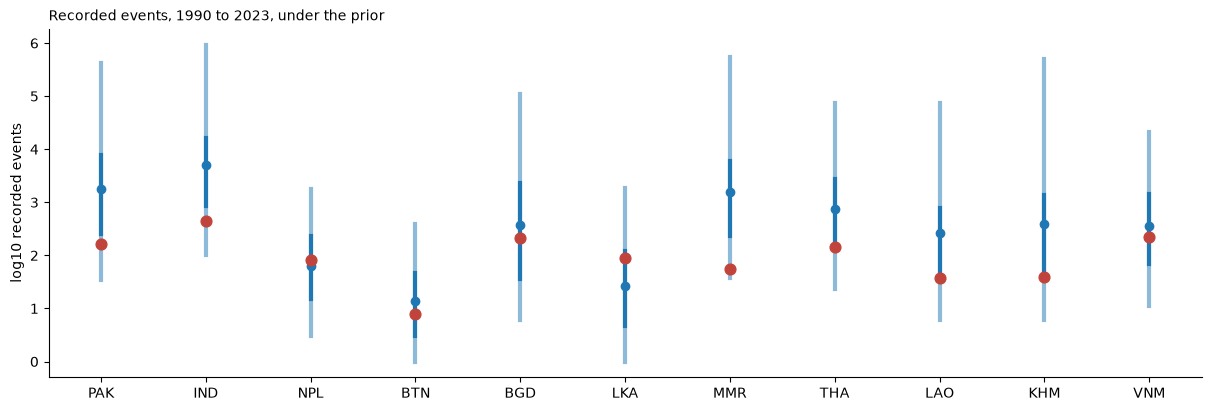

In [9]:
PRIOR_DRAWS = 1_000
OBSERVED_COLOR = "#c1443c"
OBSERVED_MARKERS = {"color": OBSERVED_COLOR, "marker": "o", "size": 60, "zorder": 4}

with event_detection_model:
    prior = pm.sample_prior_predictive(draws=PRIOR_DRAWS,
                                       var_names=["annual_count"],
                                       random_seed=SEED)

# Recorded counts span orders of magnitude under the prior, so they are compared as log10 of one plus the count.
prior_totals = xr.DataTree.from_dict({
    "prior_predictive": np.log10(prior["prior_predictive"]["annual_count"].sum("year") + 1).to_dataset(name="log10 recorded events"),
    "observed_data": xr.Dataset({"log10 recorded events": ("country", np.log10(annual_observed.sum(axis=1) + 1))}, coords={"country": list(COUNTRIES)}),
})
az.plot_ppc_interval(prior_totals,
                     group="prior_predictive",
                     visuals={"observed_markers": OBSERVED_MARKERS},
                     figure_kwargs={"figsize": (12, 4)})
axis = plt.gca()
axis.set_xticks(np.arange(n_countries), list(COUNTRIES))
axis.set_xlabel("")
axis.set_title("Recorded events, 1990 to 2023, under the prior", loc="left", fontsize=10)
plt.show()

## Fit

In [10]:
FIT_PATH = Path("fits/15_shared_year_effect_nuts.nc")

if FIT_PATH.exists():
    fit = az.from_netcdf(FIT_PATH)
else:
    with event_detection_model:
        fit = pm.sample(**sample_kwargs)
    # An interrupted run returns the draws it reached, which must not be cached as a fit.
    if fit.posterior.sizes["draw"] == sample_kwargs["draws"]:
        fit.to_netcdf(FIT_PATH)

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, naming_intercept, naming_slope, level_probability, shared_year_lengthscale, shared_year_amplitude, year_deviation_lengthscale, year_deviation_amplitude, shared_year_coefficients, year_deviation_coefficients, overdispersion]


Output()

In [11]:
SUMMARY_VARIABLES = ["slopes", "field_amplitude", "field_lengthscale", "ADM2_offset_sd", "ADM1_offset_sd", "naming_intercept", "naming_slope",
                     "shared_year_amplitude", "shared_year_lengthscale", "year_deviation_amplitude", "year_deviation_lengthscale"]
every_free = az.summary(fit, var_names=[variable.name for variable in event_detection_model.free_RVs])

pd.concat([
    az.summary(fit, var_names=SUMMARY_VARIABLES),
    pd.DataFrame({"r_hat": [every_free["r_hat"].max()], "ess_bulk": [every_free["ess_bulk"].min()]}, index=["worst over every free parameter"]),
    pd.DataFrame({"mean": [int(fit.sample_stats["diverging"].sum())]}, index=["divergences"]),
]).round(2)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
slopes[log distance to river],-0.99,0.13,-1.19,-0.78,420.19,738.96,1.01,0.01,0.00
slopes[log discharge of nearest river],-0.40,0.22,-0.75,-0.06,284.18,403.93,1.01,0.01,0.01
slopes[distance by discharge],-0.39,0.14,-0.62,-0.17,280.72,493.25,1.01,0.01,0.00
slopes[log distance to coast],-0.62,0.16,-0.88,-0.36,333.67,699.29,1.03,0.01,0.00
field_amplitude,0.64,0.30,0.13,1.16,107.14,69.61,1.06,0.03,0.01
field_lengthscale,0.12,0.09,0.04,0.27,237.33,193.35,1.03,0.01,0.01
ADM2_offset_sd,2.30,0.17,2.03,2.58,141.28,355.45,1.05,0.01,0.01
ADM1_offset_sd,0.41,0.26,0.04,0.85,74.36,174.99,1.08,0.03,0.01
naming_intercept,-2.99,0.60,-3.88,-2.13,108.14,155.76,1.06,0.07,0.07
naming_slope,0.70,0.22,0.35,1.05,239.24,323.90,1.03,0.01,0.01


## The shared year effect and the deviations

Each curve is drawn as a multiplier on recorded events, relative to its own average over the record, since the countries' intercepts take each curve's overall level. The bands are 94% highest density intervals.

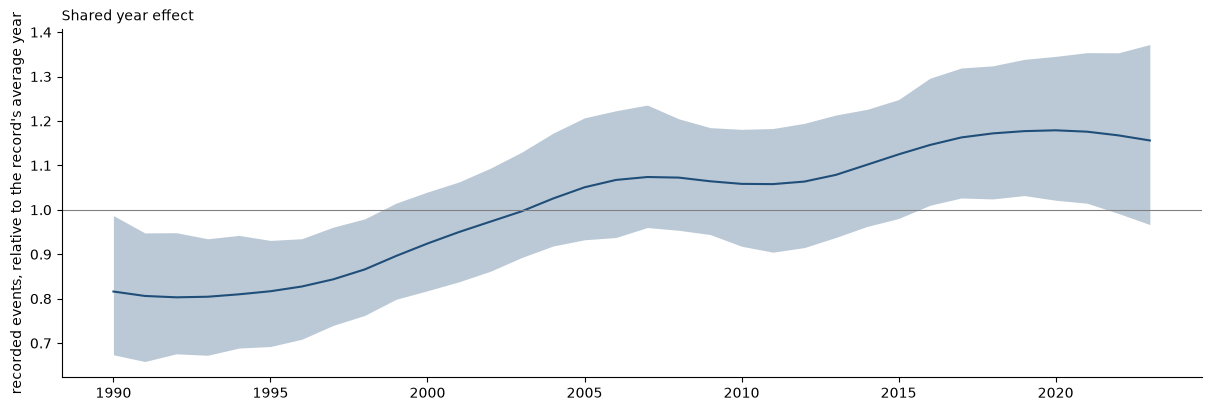

In [12]:
HDI_PROBABILITY = 0.94
SHARED_COLOR = "#1f4e79"

posterior = fit.posterior
shared_multiplier = np.exp(posterior["shared_year_effect"] - posterior["shared_year_effect"].mean("year"))
shared_band = az.hdi(shared_multiplier, prob=HDI_PROBABILITY)

figure, axis = plt.subplots(figsize=(12, 4))
axis.fill_between(years,
                  shared_band.sel(ci_bound="lower"),
                  shared_band.sel(ci_bound="upper"),
                  color=SHARED_COLOR,
                  alpha=0.3,
                  linewidth=0)
axis.plot(years,
          shared_multiplier.median(("chain", "draw")),
          color=SHARED_COLOR)
axis.axhline(1.0,
             color="0.5",
             linewidth=0.8)
axis.set_ylabel("recorded events, relative to the record's average year")
axis.set_title("Shared year effect", loc="left", fontsize=10)
plt.show()

/var/folders/7b/rzxy96cj0w751_6td3g2yss00000gn/T/ipykernel_74351/3574117896.py:27: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


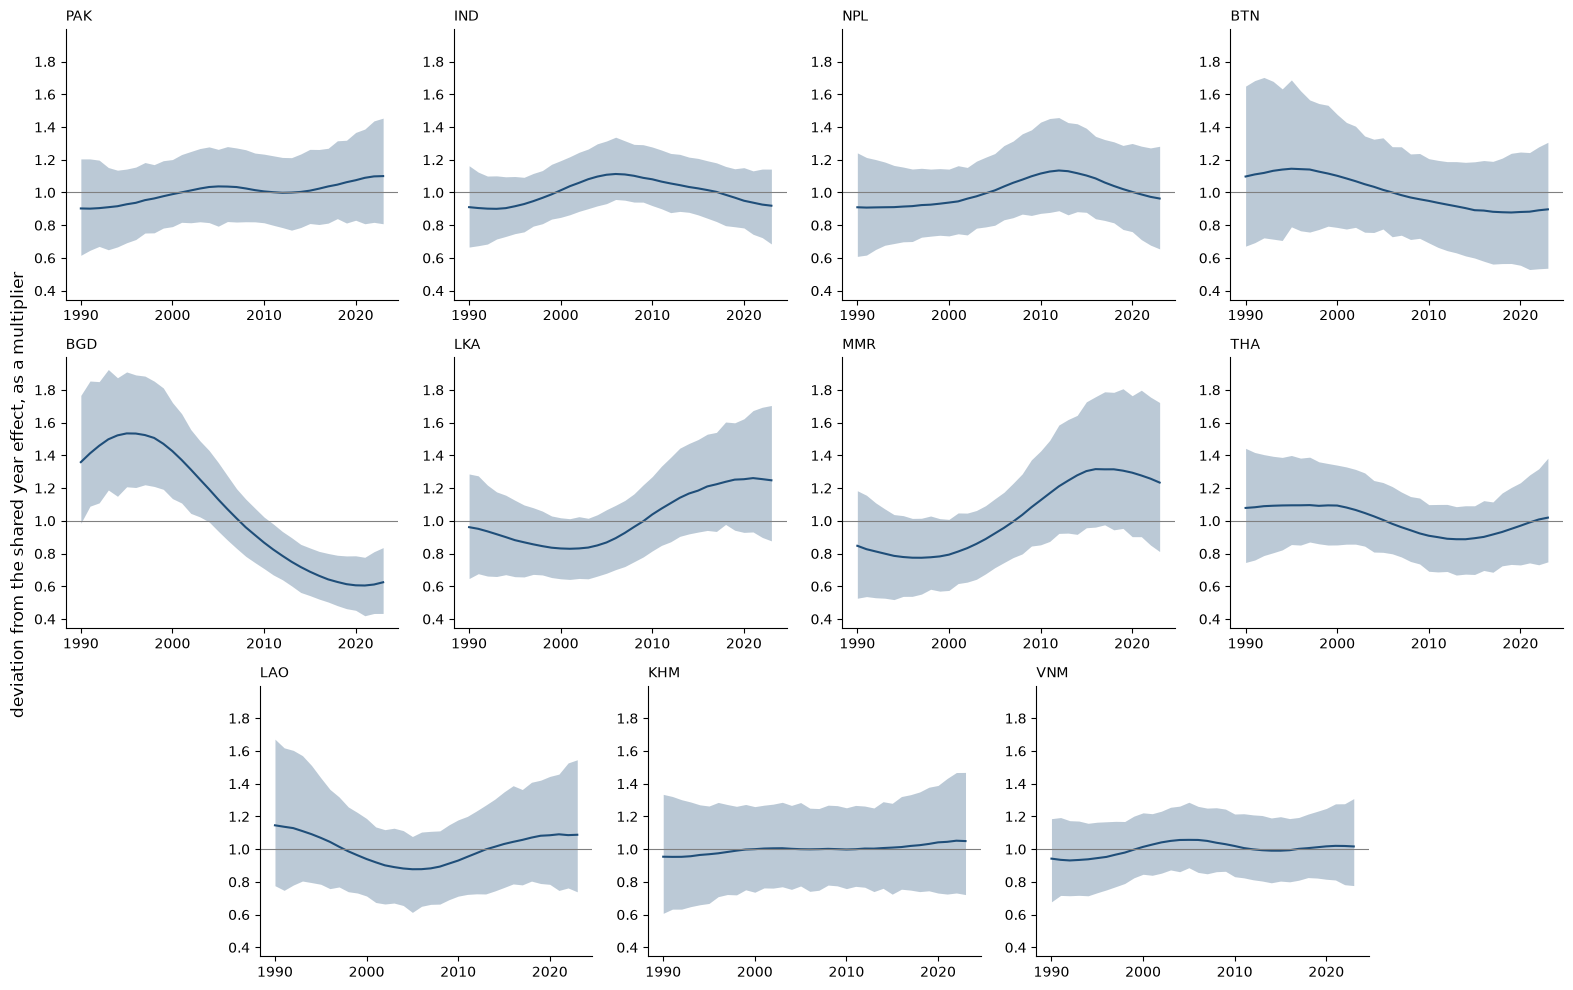

In [13]:
DEVIATION_COLUMNS = 4

deviation_multiplier = np.exp(posterior["year_deviation"] - posterior["year_deviation"].mean("year"))
deviation_band = az.hdi(deviation_multiplier, prob=HDI_PROBABILITY)
deviation_median = deviation_multiplier.median(("chain", "draw"))

layout, panels = prepare_gridspec_figure(n_cols=DEVIATION_COLUMNS, n_plots=n_countries)
figure = plt.figure(figsize=(16, 10))
axes = []
for (rows, columns), country in zip(panels, COUNTRIES, strict=True):
    axis = figure.add_subplot(layout[rows, columns], sharey=axes[0] if axes else None)
    axis.fill_between(years,
                      deviation_band.sel(country=country, ci_bound="lower"),
                      deviation_band.sel(country=country, ci_bound="upper"),
                      color=SHARED_COLOR,
                      alpha=0.3,
                      linewidth=0)
    axis.plot(years,
              deviation_median.sel(country=country),
              color=SHARED_COLOR)
    axis.axhline(1.0,
                 color="0.5",
                 linewidth=0.8)
    axis.set_title(country, loc="left", fontsize=10)
    axes.append(axis)
figure.supylabel("deviation from the shared year effect, as a multiplier")
figure.tight_layout()
plt.show()

## Posterior predictive check

As in 14: recorded events counted by country and year and split by reporting level within each country, drawn with `sample_posterior_predictive`.

In [18]:
def build_predictive_model(build_year_effect):
    """The fitted model's recorded counts by country and year, scaled by ``build_year_effect()``, and each country's split by reporting level."""
    with pm.Model(coords=COORDS) as model:
        recorded = recorded_intensity()
        recorded_by_country_level = pt.dot(atom_country, recorded.T)
        counts = annual_count(recorded_by_country_level.sum(axis=1), build_year_effect())
        pm.Multinomial("level_count",
                       n=counts.sum(axis=1),
                       p=recorded_by_country_level / recorded_by_country_level.sum(axis=1, keepdims=True),
                       dims=("country", "level"))

    return model


with build_predictive_model(build_year_effect=year_effect):
    ppc = pm.sample_posterior_predictive(fit,
                                         var_names=["annual_count", "level_count"],
                                         random_seed=SEED)

ppc["observed_data"] = xr.Dataset({
    "annual_count": (("country", "year"), annual_observed),
    "level_count": (("country", "level"), record.groupby(["country", "level"]).size().unstack(fill_value=0).reindex(index=list(COUNTRIES), columns=list(LEVELS), fill_value=0).to_numpy()),
}, coords={"country": list(COUNTRIES), "year": years, "level": list(LEVELS)})

Sampling: [annual_count, level_count]


Output()

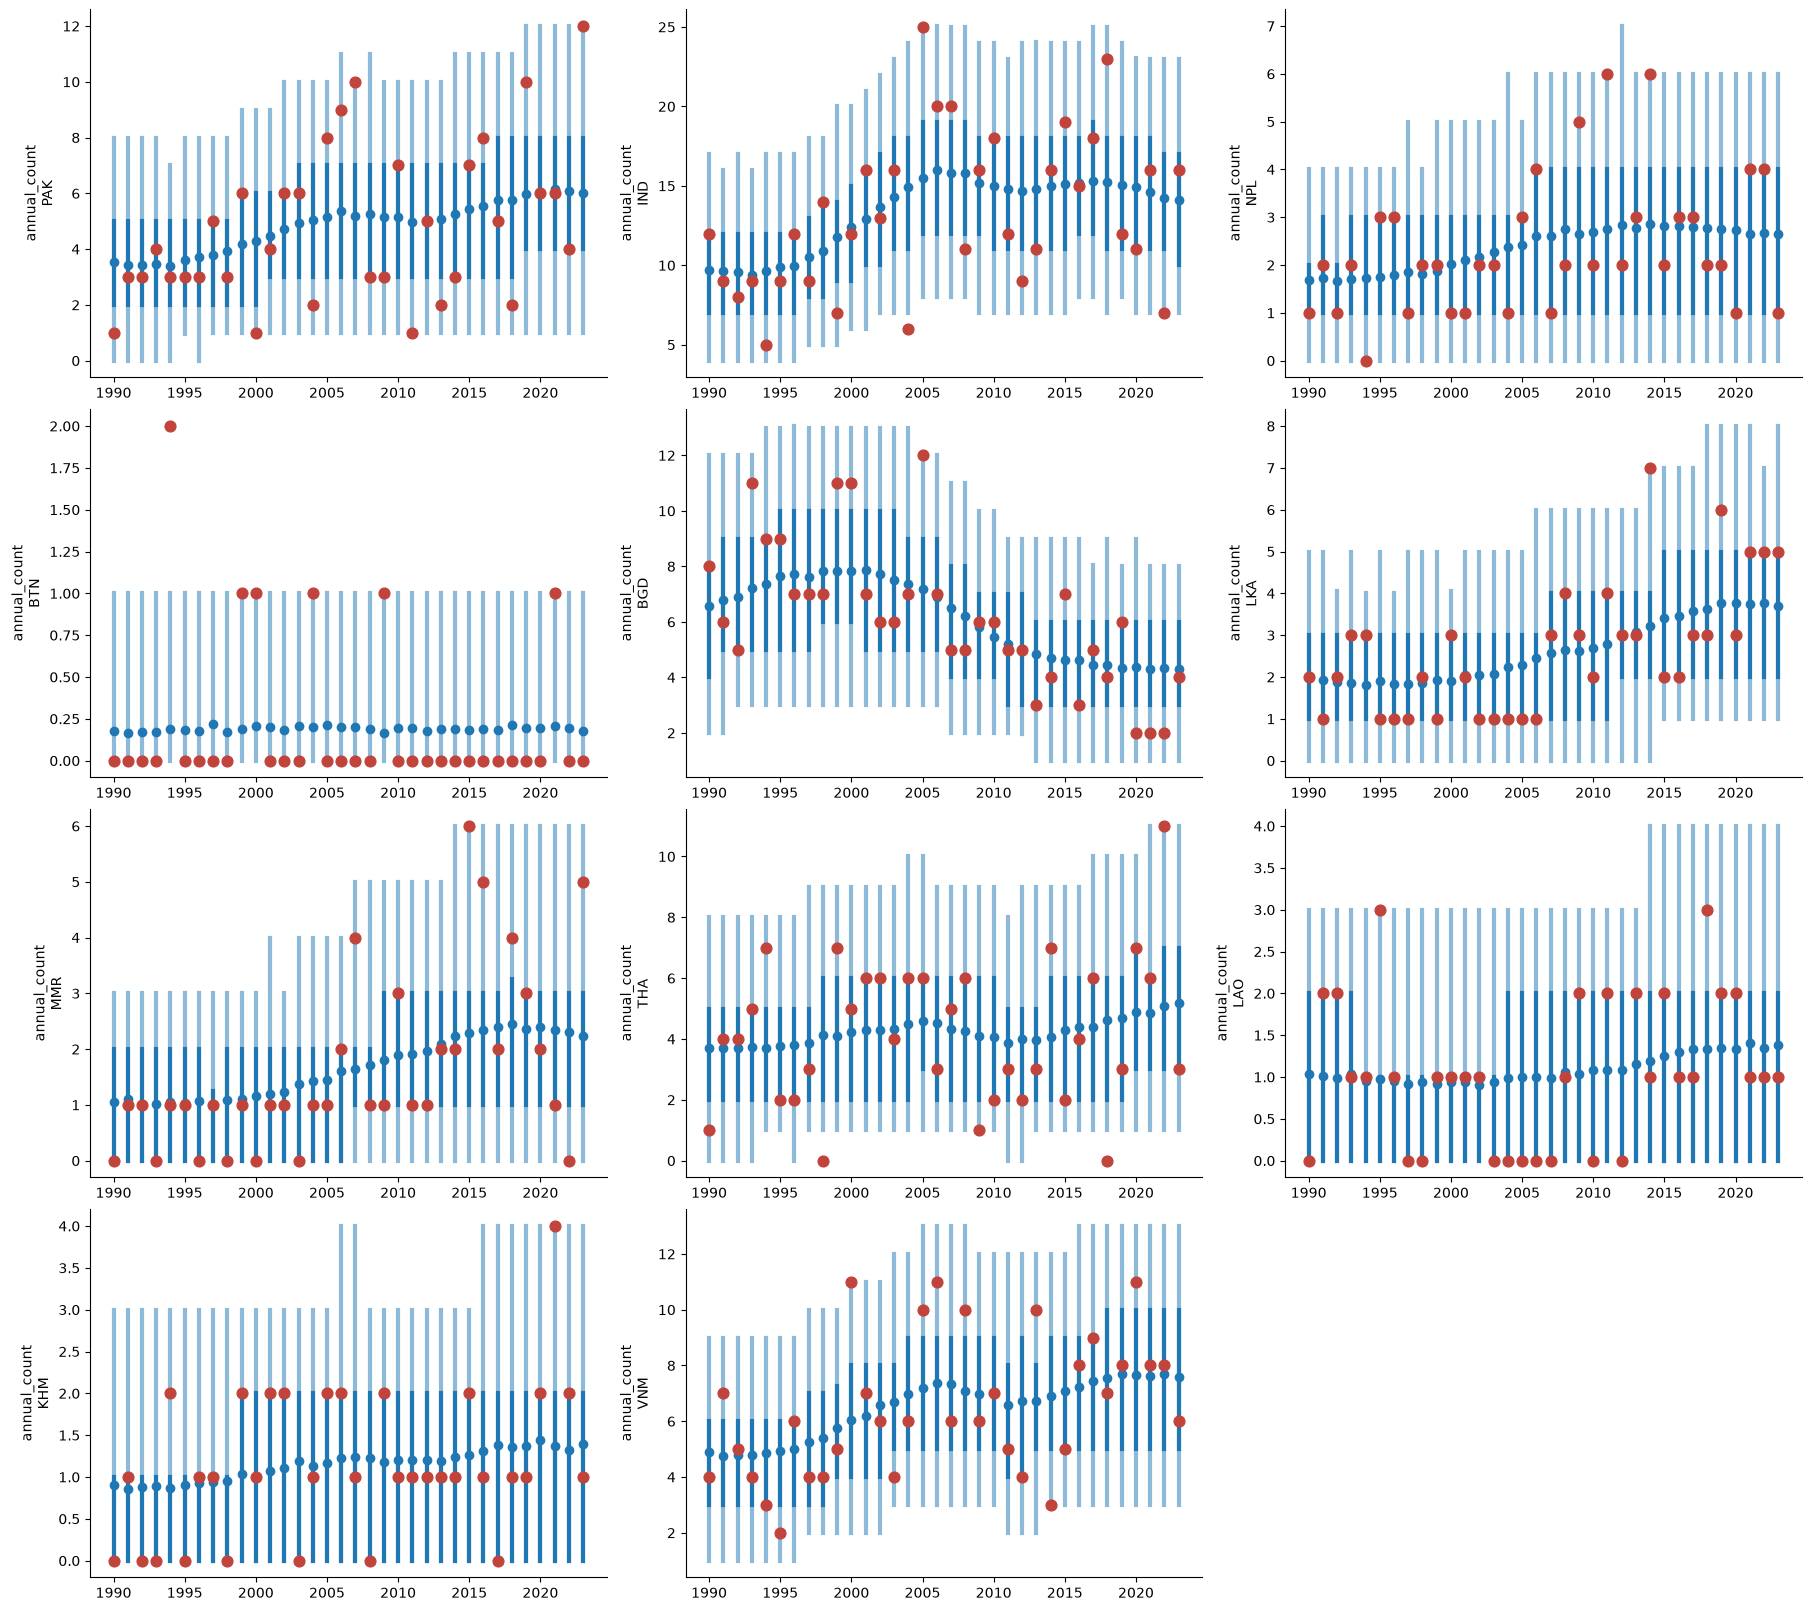

In [15]:
YEAR_TICK_STEP = 5

annual_plot = az.plot_ppc_interval(ppc,
                                   var_names=["annual_count"],
                                   visuals={"observed_markers": OBSERVED_MARKERS},
                                   cols=["country"],
                                   col_wrap=3,
                                   figure_kwargs={"figsize": (18, 16), "sharey": False})
for axis in annual_plot.viz["figure"].item().axes:
    axis.set_xticks(np.arange(0, YEARS, YEAR_TICK_STEP), years[::YEAR_TICK_STEP])
    axis.set_xlabel("")
plt.show()

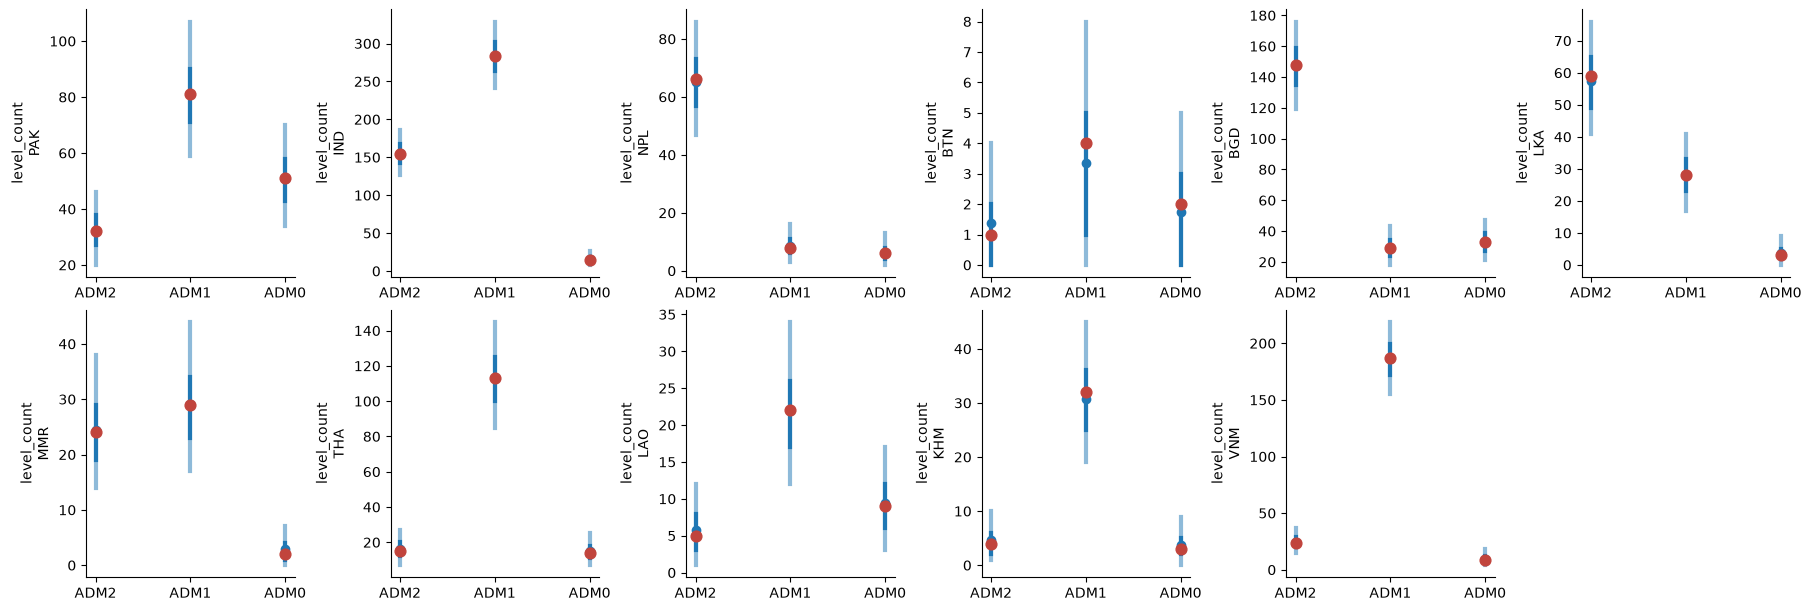

In [16]:
level_plot = az.plot_ppc_interval(ppc,
                                  var_names=["level_count"],
                                  visuals={"observed_markers": OBSERVED_MARKERS},
                                  cols=["country"],
                                  col_wrap=6,
                                  figure_kwargs={"figsize": (18, 6), "sharey": False})
for axis in level_plot.viz["figure"].item().axes:
    axis.set_xticks(np.arange(len(LEVELS)), list(LEVELS))
    axis.set_xlabel("")
plt.show()

## What the fit says

The fit took 27 minutes with 12 divergences, 6 in each of two chains. The worst r-hat over every free parameter is 1.09, on the state offset scale, with a bulk ESS of 74. Every year-effect parameter has an r-hat of 1.02 or less. The spatial and detection results match 14's to the second decimal in most places: the river slope is -0.99, the naming slope 0.70.

The region's recorded events rose over the record. The shared curve's mean over 2016 to 2020 is 1.45 times its mean over 1990 to 1994 (94% HDI 1.13 to 1.83), and 99.7% of draws put the later years higher. Most of the rise falls between the late 1990s and 2005, with a second, smaller one after 2012. The shared amplitude is 0.31 (89% interval 0.11 to 0.67) with a lengthscale of 12 years.

The countries depart from that curve about as much as the curve moves. The deviations' amplitude is 0.34 (0.19 to 0.53), with a lengthscale of 12 years. Bangladesh is the largest: its deviation falls from 1.5 times the shared curve in the mid-1990s to 0.6 by 2020, and its 2016 to 2020 deviation is 0.43 times its 1990 to 1994 one, with no draw above 1. Myanmar's rises by 1.61 times (95% of draws above 1) and Sri Lanka's by 1.32 (90%), so recorded events there grew faster than the region's. The other eight countries' deviations stay within about 20% of the shared curve and their intervals cover 1 throughout. Every country's level split and 373 of 374 country-years fall inside their 94% predictive intervals, as in 14.

## Global temperature in the shared year effect

Does the region's shared year effect follow global temperature? The shared curve becomes a slope on the standardized global mean temperature anomaly plus a smooth residual,

$$s_t = \gamma \, z_t + r_t,$$

with $r$ the shared Matern 5/2 process of the section above and the deviations unchanged. The anomaly is HadCRUT5's analysis ensemble mean, averaged over its grid with cos-latitude weights and then over each year's months. It rises close to steadily over 1990 to 2023, and a residual with a lengthscale of a decade can absorb a steady rise as easily as the slope can, so the slope reads mainly what the residual cannot: the temperature series' year-to-year departures from its own trend. The slope's prior is normal with scale 0.5 on the log of recorded events per standard deviation of temperature, the scale of the shared amplitude's prior.

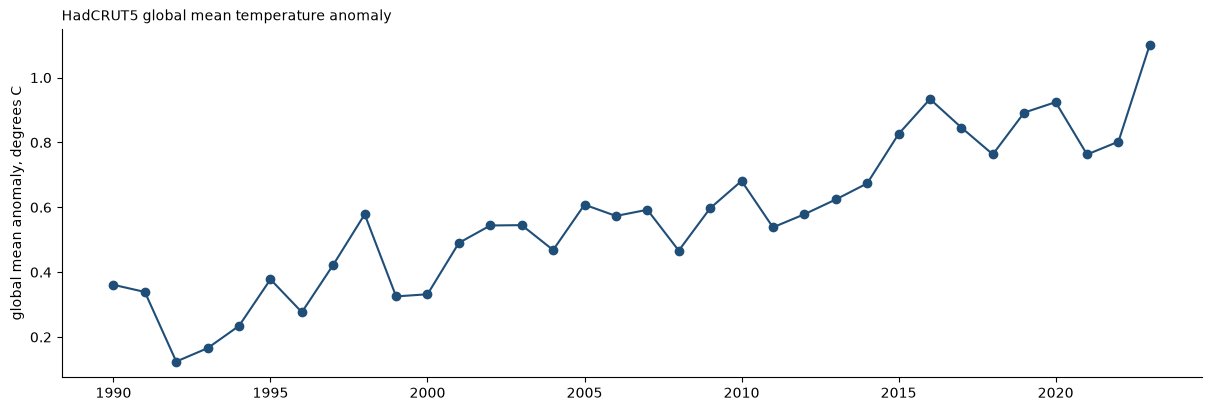

In [20]:
gridded_temperature = xr.open_dataset(fetch(HADCRUT, CACHE_DIR))["tas_mean"]
latitude_weights = np.cos(np.deg2rad(gridded_temperature["latitude"]))
global_temperature = (gridded_temperature.weighted(latitude_weights)
                      .mean(("latitude", "longitude"))
                      .groupby("time.year")
                      .mean()
                      .sel(year=slice(FIRST_YEAR, LAST_YEAR)))
temperature_z = standardized(global_temperature.to_numpy())

figure, axis = plt.subplots(figsize=(12, 4))
axis.plot(global_temperature["year"],
          global_temperature,
          color=SHARED_COLOR,
          marker="o")
axis.set_ylabel("global mean anomaly, degrees C")
axis.set_title("HadCRUT5 global mean temperature anomaly", loc="left", fontsize=10)
plt.show()

In [21]:
TEMPERATURE_SLOPE_PRIOR = 0.5


def temperature_year_effect():
    """Each country's year effect, with the shared curve a slope on global temperature plus a smooth residual."""
    temperature_slope = pm.Normal("temperature_slope",
                                  mu=0.0,
                                  sigma=TEMPERATURE_SLOPE_PRIOR)
    residual = pm.Deterministic("shared_year_residual", shared_year_process(), dims="year")

    return combined_year_effect(temperature_slope * temperature_z + residual, year_deviation())


temperature_model = build_event_detection_model(build_year_effect=temperature_year_effect)

In [22]:
TEMPERATURE_FIT_PATH = Path("fits/15_temperature_shared_year_nuts.nc")

if TEMPERATURE_FIT_PATH.exists():
    temperature_fit = az.from_netcdf(TEMPERATURE_FIT_PATH)
else:
    with temperature_model:
        temperature_fit = pm.sample(**sample_kwargs)
    # An interrupted run returns the draws it reached, which must not be cached as a fit.
    if temperature_fit.posterior.sizes["draw"] == sample_kwargs["draws"]:
        temperature_fit.to_netcdf(TEMPERATURE_FIT_PATH)

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, naming_intercept, naming_slope, level_probability, temperature_slope, shared_year_lengthscale, shared_year_amplitude, shared_year_coefficients, year_deviation_lengthscale, year_deviation_amplitude, year_deviation_coefficients, overdispersion]


Output()

In [25]:
YEAR_VARIABLES = ["shared_year_amplitude", "shared_year_lengthscale", "year_deviation_amplitude", "year_deviation_lengthscale"]
temperature_free = az.summary(temperature_fit, var_names=[variable.name for variable in temperature_model.free_RVs])

print(f"worst r_hat over every free parameter {temperature_free['r_hat'].max():.2f}, divergences {int(temperature_fit.sample_stats['diverging'].sum())}")
pd.concat([
    az.summary(temperature_fit, var_names=["temperature_slope", *YEAR_VARIABLES])[["mean", "sd", "eti89_lb", "eti89_ub", "r_hat"]].add_prefix("with temperature, "),
    az.summary(fit, var_names=YEAR_VARIABLES)[["mean", "sd"]].add_prefix("without, "),
], axis=1).round(2)

worst r_hat over every free parameter 1.15, divergences 3


,"with temperature, mean","with temperature, sd","with temperature, eti89_lb","with temperature, eti89_ub","with temperature, r_hat","without, mean","without, sd"
temperature_slope,0.12,0.06,0.02,0.20,1.01,NaN,NaN
shared_year_amplitude,0.17,0.16,0.02,0.47,1.01,0.31,0.19
shared_year_lengthscale,13.21,16.92,3.75,32.08,1.01,11.67,6.74
year_deviation_amplitude,0.34,0.10,0.20,0.52,1.01,0.34,0.11
year_deviation_lengthscale,11.93,4.17,6.52,19.30,1.00,12.01,4.34


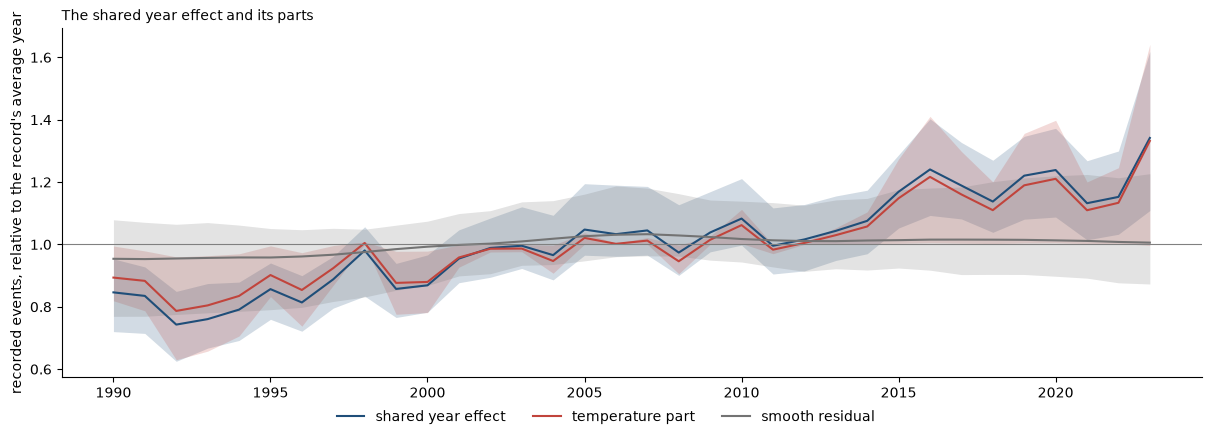

In [24]:
TEMPERATURE_COLOR = "#c1443c"

temperature_posterior = temperature_fit.posterior
shared_parts = {
    "shared year effect": (temperature_posterior["shared_year_effect"], SHARED_COLOR),
    "temperature part": (temperature_posterior["temperature_slope"] * xr.DataArray(temperature_z, dims="year", coords={"year": years}), TEMPERATURE_COLOR),
    "smooth residual": (temperature_posterior["shared_year_residual"], "0.45"),
}

figure, axis = plt.subplots(figsize=(12, 4))
for label, (part, color) in shared_parts.items():
    multiplier = np.exp(part - part.mean("year"))
    band = az.hdi(multiplier, prob=HDI_PROBABILITY)
    axis.fill_between(years,
                      band.sel(ci_bound="lower"),
                      band.sel(ci_bound="upper"),
                      color=color,
                      alpha=0.2,
                      linewidth=0)
    axis.plot(years,
              multiplier.median(("chain", "draw")),
              color=color,
              label=label)
axis.axhline(1.0,
             color="0.5",
             linewidth=0.8)
axis.set_ylabel("recorded events, relative to the record's average year")
axis.set_title("The shared year effect and its parts", loc="left", fontsize=10)
handles, labels = axis.get_legend_handles_labels()
figure.legend(handles=handles,
              labels=labels,
              loc="lower center",
              bbox_to_anchor=(0.5, -0.08),
              ncol=len(labels),
              frameon=False)
plt.show()

In [27]:
COMPARED_FITS = {
    "smooth shared curve": (fit, event_detection_model),
    "temperature plus residual": (temperature_fit, temperature_model),
}

# The comparison scores each country-year's recorded count, the term the two models differ in.
annual_scores = {}
for name, (compared_fit, compared_model) in COMPARED_FITS.items():
    pointwise = pm.compute_log_likelihood(compared_fit,
                                          var_names=["annual_count"],
                                          model=compared_model,
                                          extend_inferencedata=False)
    annual_scores[name] = xr.DataTree.from_dict({"posterior": compared_fit.posterior.to_dataset()[["intercept"]],
                                                 "log_likelihood": pointwise})

az.compare(annual_scores)

Output()

Output()

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
temperature plus residual,0,0.00,0.00,NaN,,,23.20,-690.00,16.00,0.90
smooth shared curve,1,-1.00,1.40,0.71,|elpd_diff| < 4,,23.90,-690.00,17.00,0.10


### What the temperature term says

The fit took 26 minutes with 3 divergences. Every year-effect parameter has an r-hat of 1.01 or less, and the worst over every free parameter is 1.15, on one Uttar Pradesh district's offset.

The temperature slope is 0.12 per standard deviation of the global anomaly (89% interval 0.02 to 0.20). The anomaly's standard deviation over 1990 to 2023 is 0.23 degrees, so the slope is 0.51 on the log scale per degree, about 67% more recorded events per degree. The temperature part carries the whole of the shared curve's rise and adds the series' year-to-year swings to it, the dip after Pinatubo in 1992 and the peaks of 1998, 2016 and 2023. The smooth residual's amplitude falls from 0.31 to 0.17 (0.02 to 0.47), and the country deviations do not move.

Leave-one-out cross-validation on the 374 country-year counts does not separate the two models: the temperature model's expected log predictive density is higher by 1.0, with a standard error of 1.4, against 4 as the smallest difference worth reading. The year-to-year swings in global temperature do not predict the swings in recorded events, so the slope is fitted from the rise the two series share. EM-DAT's coverage growing over the record would produce that rise equally well, and this record does not tell the two apart.